# Paper experiments, final

Every figure and table the paper reports, from one config cell.

Two conventions live here side by side and are labelled wherever they appear:

- **pooled**, every source column weighted equally, which is what the rest of
  this repo does and what the headline numbers use;
- **per pair**, the mean over schema pairs, which is Magneto's convention and
  is what Figure 1 uses so the numbers are comparable with their Figure 6.

They are different numbers. A pair with 16 columns counts like one with 179
under the per-pair mean.

In [1]:
import json
import sys
from pathlib import Path

import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

REPO = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(REPO))

import corpora
from evaluation import competitors, walk_rules
from evaluation import scoring as report
from schemaoracle import cache, inventory, pruning

pd.set_option("display.width", 220)
pd.set_option("display.max_columns", 80)

RUNS = REPO / "results" / "runs"
COMPETITOR_RUNS = REPO / "results" / "competitors"
FIGDIR = REPO / "figures"
TABDIR = REPO / "results"

RETRIEVER = "qwen"
ORDERS = ["qwen", "magneto"]
ARMS = ["rerank", "gated", "paged"]
TOP_K, WINDOW, TAU = 20, 20, 0.0
VARIANT = "tgt-match-retriever"

# One hue family per model, one shade per protocol inside it, so a reader can
# read model from the colour and protocol from the shade without the legend.
# Light to dark is rerank, gated, paged: the order the arms see more of the
# ordering.
MODELS = {
    "claude-sonnet-5": ("Sonnet 5", "#0f766e"),
    "deepseek-v4.1-flash-cloud": ("V4.1 Flash", "#2171b5"),
}
SHADES = {
    "claude-sonnet-5": {"rerank": "#7fcdbb", "gated": "#35a79c",
                        "paged": "#0b5351"},
    "deepseek-v4.1-flash-cloud": {"rerank": "#9ecae1", "gated": "#4292c6",
                                  "paged": "#08458a"},
}
# The baselines are not a family, so each takes a hue of its own, kept clear of
# both ramps. Magneto is red, as in its own figures.
BASELINE = {"retriever": "#475569", "COMA": "#e07b39",
            "COMA, inst.": "#9c6644", "Jaccard-Lev.": "#8c6bb1",
            "Magneto": "#c0392b"}
FILTERS = {"": "none", "zerosrc": "zero-source", "mutual": "mutual",
           "mutual-zero": "mutual+zero-target", "zero": "zero-target"}

GDC = "gdc"
VALENTINE = ["valentine/opendata", "valentine/chembl", "valentine/tpc-di",
             "valentine/wikidata", "valentine/magellan"]
SHORT = {"valentine/opendata": "OpenData", "valentine/chembl": "ChEMBL",
         "valentine/tpc-di": "TPC-DI", "valentine/wikidata": "Wikidata",
         "valentine/magellan": "Magellan"}

MAGNETO_LLM = "deepseek/deepseek-v4.1-flash"
COMPETITORS = {"coma": "COMA", "coma-instances": "COMA, inst.",
               "jaccard-levenshtein": "Jaccard-Lev."}

C_INK, C_MUTE = "#1e293b", "#94a3b8"
C_RET, C_COMP = BASELINE["retriever"], "#cbd5e1"


def colour_of(model_key, arm):
    """The shade for one (model, protocol) cell."""
    return SHADES.get(model_key, {}).get(arm, MODELS[model_key][1])


def colour_for(label, arm=None, model_key=None):
    """The colour for any bar: a baseline by name, or a model-protocol cell."""
    if label in BASELINE:
        return BASELINE[label]
    if model_key is not None and arm is not None:
        return colour_of(model_key, arm)
    return C_COMP
mpl.rcParams.update({
    "figure.dpi": 130, "savefig.dpi": 400, "savefig.bbox": "tight",
    "font.family": "serif", "font.serif": ["DejaVu Serif"], "font.size": 7.5,
    "text.color": C_INK, "xtick.color": C_INK, "ytick.color": C_INK,
    "axes.edgecolor": C_INK, "axes.labelcolor": C_INK,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.16, "grid.linewidth": 0.4,
    "pdf.fonttype": 42, "ps.fonttype": 42,
})
W1, W2 = 3.4, 7.0            # single and double column


def save(fig, name):
    for ext in ("pdf", "png"):
        fig.savefig(FIGDIR / f"{name}.{ext}")
    print(f"wrote figures/{name}.pdf and .png")


def load(corpus):
    """Pairs, their filename-safe names, and the two corpus sizes."""
    pairs = corpora.load(corpus)
    names = [cache.fs_safe(p["name"]) for p in pairs]
    n_src = sum(p["source_df"].shape[1] for p in pairs)
    n_gold = sum(len({str(s) for s, _ in p["ground_truth"]}) for p in pairs)
    return pairs, names, n_src, n_gold


CORPUS = {c: load(c) for c in [GDC] + VALENTINE}
for c, (pairs, _, n_src, n_gold) in CORPUS.items():
    print(f"{c:22s} {len(pairs):4d} pairs  {n_src:6,} columns  "
          f"{n_gold:6,} with gold   ceiling |S_M|/|S| = {n_gold / n_src:.3f}")

C:\Users\muril\SchemaOracle\corpora\registry.py:129: UserWarning: valentine/wikidata: ground truth names 2 source column(s) that are not in the source frame (Wikidata/Musicians/Musicians_unionable: givenName; Wikidata/Musicians/Musicians_viewunion: givenName). No matcher can reach them, and they are counted by MRR but not by the precision, so the two use different denominators.
  _warn_unreachable_gold(name, out)


gdc                      10 pairs     569 columns     165 with gold   ceiling |S_M|/|S| = 0.290
valentine/opendata      180 pairs   6,876 columns   4,572 with gold   ceiling |S_M|/|S| = 0.665
valentine/chembl        180 pairs   3,060 columns   2,052 with gold   ceiling |S_M|/|S| = 0.671
valentine/tpc-di        180 pairs   2,916 columns   1,980 with gold   ceiling |S_M|/|S| = 0.679
valentine/wikidata        4 pairs      60 columns      40 with gold   ceiling |S_M|/|S| = 0.667
valentine/magellan        7 pairs      41 columns      41 with gold   ceiling |S_M|/|S| = 1.000


## The palette

One hue family per model and one shade per protocol inside it, so colour reads
as the model and shade as the protocol. Each published matcher takes a flat
hue of its own, kept clear of both ramps.

wrote figures/fig0_palette.pdf and .png


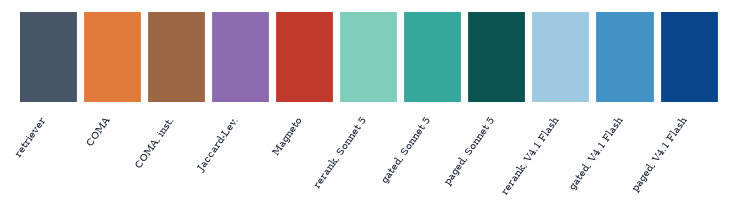

In [2]:
fig, ax = plt.subplots(figsize=(W2, 0.9))
swatches = [(lab, c) for lab, c in BASELINE.items()]
swatches += [(f"{a}, {lab}", colour_of(k, a))
             for k, (lab, _) in MODELS.items() for a in ARMS]
for i, (lab, c) in enumerate(swatches):
    ax.add_patch(plt.Rectangle((i, 0), 0.86, 1, color=c))
    ax.annotate(lab, (i + 0.43, -0.15), ha="right", va="top", rotation=55,
                fontsize=5.8, annotation_clip=False)
ax.set_xlim(0, len(swatches))
ax.set_ylim(0, 1)
ax.axis("off")
save(fig, "fig0_palette")
plt.show()

## The design

A cell enters a figure only if it is whole on every study of its corpus. The
fallback gate is judged on the pooled cell, not per run: on a small study one
reply that trailed off is already above the 2% separator.

In [3]:
MAX_FB = inventory.MAX_FALLBACK

# Unreadable columns, judged on the pooled cell rather than per run.
# `inventory.check` drops a whole run for one, which on Valentine costs the
# study's 14 to 17 columns. An unanswered column already scores as zero, so a
# handful is reportable; a cell where they are systemic is not.
MAX_STUCK = 0.01


def tagged(frame):
    return frame.assign(
        model=frame["arm"].str.split("__").str[0],
        variant=frame["arm"].str.split("__").str[1:].str.join("__"))


def cells(corpus, *, order=RETRIEVER, prune="", kinds=ARMS, window=WINDOW,
          tau=TAU, top_k=TOP_K):
    """{(arm, model): runs} for the cells that are whole and model-answered."""
    pairs, names, n_src, _ = CORPUS[corpus]
    inv = tagged(inventory.scan(RUNS, corpus=corpus, pairs=names,
                                kinds=tuple(kinds)))
    inv = inv[(inv["rep"] == 1) & (inv["prune"] == prune)
              & (inv["retriever"] == order) & (inv["variant"] == VARIANT)
              & inv["model"].isin(MODELS)
              & ((inv["kind"] != "paged") & (inv["top_k"] == top_k)
                 | (inv["kind"] == "paged") & (inv["window"] == window)
                 & (inv["threshold"] == tau))]
    ok = tagged(inventory.check(inv, verbose=False, max_fallback=1.0,
                                drop_errored=False))
    out, short, admitted = {}, [], []
    for arm in kinds:
        for m in MODELS:
            runs = ok[(ok["kind"] == arm) & (ok["model"] == m)]
            n = int(runs["n_columns"].sum())
            if set(runs["pair"]) != set(names) or n != n_src:
                short.append((arm, MODELS[m][0], len(set(runs["pair"])), n))
                continue
            fb = runs["n_fallback"].sum() / max(n, 1)
            if fb > MAX_FB:
                short.append((arm, MODELS[m][0], "retriever answered",
                              f"{fb:.1%}"))
                continue
            stuck = runs["n_stuck"].sum() / max(n, 1)
            if stuck > MAX_STUCK:
                short.append((arm, MODELS[m][0], "unreadable",
                              f"{stuck:.1%}"))
                continue
            if stuck:
                admitted.append((arm, MODELS[m][0], int(runs["n_stuck"].sum()),
                                 n))
            out[arm, m] = runs
    for arm, model, n_stuck, n in admitted:
        print(f"  {corpus} / {arm} / {model}: {n_stuck} of {n} columns had no "
              f"readable reply ({n_stuck / n:.2%}), scored as unanswered")
    return out, short, pairs, n_src


def scored(corpus, runs_of, pairs, *, group_by=None):
    """One row per (arm, model), or per group when `group_by` is given."""
    rows = []
    for (arm, m), runs in runs_of.items():
        s = report.score(runs, pairs, results=RUNS, corpus=corpus, kind=arm,
                         group_by=group_by)
        for r in s.to_dict("records"):
            rows.append({**r, "arm": arm, "model": MODELS[m][0], "key": m})
    return pd.DataFrame(rows)


def in_arm_order(frame, col="arm"):
    """rerank, gated, paged. A groupby sorts alphabetically otherwise."""
    return frame.sort_values(
        col, key=lambda s: s.map({a: i for i, a in enumerate(ARMS)}))


def terms(row, n_gold, n_src):
    """
    MRR with absence splits into a ranking term and an abstention term:

        MRR0 = (|S_M|/|S|) MRR + (1 - |S_M|/|S|) abstain_recall

    so the first term cannot exceed |S_M|/|S|, which is the ceiling drawn in
    every MRR0 panel.
    """
    w = n_gold / n_src
    return w * row["mrr"], (1 - w) * row["abstain_recall"]


DESIGN = {}
for c in [GDC] + VALENTINE:
    runs_of, short, pairs, n_src = cells(c)
    DESIGN[c] = runs_of
    got = sorted({MODELS[m][0] for _, m in runs_of})
    print(f"{c:22s} whole: {len(runs_of)} cells, models {got}")
    for s in short:
        print(f"    not in: {s}")

gdc                    whole: 6 cells, models ['Sonnet 5', 'V4.1 Flash']


valentine/opendata     whole: 6 cells, models ['Sonnet 5', 'V4.1 Flash']


  valentine/chembl / gated / Sonnet 5: 2 of 3060 columns had no readable reply (0.07%), scored as unanswered
  valentine/chembl / paged / Sonnet 5: 4 of 3060 columns had no readable reply (0.13%), scored as unanswered
valentine/chembl       whole: 6 cells, models ['Sonnet 5', 'V4.1 Flash']


valentine/tpc-di       whole: 6 cells, models ['Sonnet 5', 'V4.1 Flash']


valentine/wikidata     whole: 6 cells, models ['Sonnet 5', 'V4.1 Flash']


valentine/magellan     whole: 6 cells, models ['Sonnet 5', 'V4.1 Flash']


## Figure 1: GDC-SM, per-pair means

Magneto's convention, so the bars are comparable with their Figure 6. The left
panel is MRR, the right is MRR with absence, split into its two terms. The
dashed line in the right panel is $|S_M|/|S| = 0.29$: the most the ranking term
can contribute, however good the ranking is.

In [4]:
def competitor_rows(corpus, pairs, *, order=RETRIEVER, per_pair=False):
    """
    The published matchers, scored the way the arms are. `score_competitors`
    pools, so the per-pair mean is taken by scoring one pair at a time.
    """
    names = dict(COMPETITORS)
    names[competitors.magneto_llm_tag(order, MAGNETO_LLM)] = "Magneto"
    groups = [[p] for p in pairs] if per_pair else [list(pairs)]
    out = []
    for group in groups:
        frame = report.score_competitors(group, list(names),
                                         results=COMPETITOR_RUNS,
                                         corpus=corpus, retriever=order)
        if len(frame):
            if per_pair:
                frame = frame.assign(pair=cache.fs_safe(group[0]["name"]))
            out.append(frame)
    if not out:
        return pd.DataFrame()
    frame = pd.concat(out, ignore_index=True)
    return frame.assign(label=frame["matcher"].map(names))


def retriever_row(corpus, pairs, names, *, order=RETRIEVER):
    o, g = report.retrieval_rankings(pairs, results=RUNS, corpus=corpus,
                                     retriever=order, covered=names)
    return report.metrics(o, g, {c: True for c in o})


def per_study(corpus, runs_of, pairs, names, *, order=RETRIEVER):
    """
    One row per (method, study). Magneto reports the mean over schema pairs
    rather than over columns, so a 16-column study counts like a 179-column
    one. The pooled numbers are in the tables; these are for the figures.
    """
    rows = []
    for p in pairs:
        nm = cache.fs_safe(p["name"])
        # A pair whose order was never cached is absent, not zero.
        if not cache.retrieval_path(RUNS, corpus, p["name"], order).exists():
            continue
        o, g = report.retrieval_rankings([p], results=RUNS, corpus=corpus,
                                         retriever=order, covered=[nm])
        rows.append({"label": "retriever", "pair": nm, "colour": C_RET,
                     **report.metrics(o, g, {c: True for c in o})})
    comp = competitor_rows(corpus, pairs, order=order, per_pair=True)
    for x in comp.to_dict("records") if len(comp) else []:
        rows.append({**x, "colour": colour_for(x["label"])})
    for (arm, m), runs in runs_of.items():
        colour = colour_of(m, arm)
        for x in report.score(runs, pairs, results=RUNS, corpus=corpus,
                              kind=arm, group_by="pair").to_dict("records"):
            rows.append({**x, "label": f"{arm}, {MODELS[m][0]}",
                         "arm": arm, "colour": colour})
    return pd.DataFrame(rows)


def mean_spread(frame, fields, ceiling=None):
    """
    Mean and sample standard deviation over studies, in figure order:
    retriever, the published matchers, then our protocols.

    The two terms of MRR with absence are computed per study, under that
    study's own |S_M|/|S|, and only then averaged. Using the corpus ratio on an
    averaged MRR does not sum back to the averaged MRR0: GDC's per-study ratio
    runs from 0.09 to 0.88, so no single ratio describes a study.
    """
    frame = frame.copy()
    w = frame["n_gold_columns"] / frame["n_columns"]
    frame["rank term"] = w * frame["mrr"]
    frame["abst term"] = (1 - w) * frame["abstain_recall"]
    fields = list(fields) + ["rank term", "abst term"]
    agg = frame.groupby("label", as_index=False).agg(
        **{f"{f}_{s}": (f, s) for f in fields for s in ("mean", "std")},
        n_studies=("pair", "nunique"))
    colour = frame.groupby("label")["colour"].first()
    arm = frame.groupby("label")["arm"].first() if "arm" in frame else None
    agg["colour"] = agg["label"].map(colour)
    order = {"retriever": 0}
    for i, lab in enumerate(["COMA", "COMA, inst.", "Jaccard-Lev.", "Magneto"]):
        order[lab] = 1 + i
    def rank(lab):
        if lab in order:
            return (0, order[lab], "")
        a = arm.get(lab, "") if arm is not None else ""
        return (1, ARMS.index(a) if a in ARMS else 9, lab)
    agg = agg.iloc[[i for i, _ in sorted(enumerate(agg["label"]),
                                         key=lambda kv: rank(kv[1]))]]
    agg = agg.rename(columns={"rank term_mean": "rank term",
                              "abst term_mean": "abst term"})
    return agg.reset_index(drop=True)


def bar_panel(ax, labels, values, colours, *, split=None, ceiling=None,
              ylabel="", err=None):
    """`err` is the spread over studies, clipped so a whisker cannot leave [0, 1]."""
    x = np.arange(len(labels))
    if split is None:
        ax.bar(x, values, color=colours, width=0.74, edgecolor="white", lw=0.4)
        top = values
    else:
        rank, abst = split
        ax.bar(x, rank, color=colours, width=0.74, edgecolor="white", lw=0.4)
        ax.bar(x, abst, bottom=rank, color=colours, width=0.74, alpha=0.42,
               edgecolor="white", lw=0.4)
        top = np.asarray(rank) + np.asarray(abst)
    if err is not None:
        e = np.nan_to_num(np.asarray(err, dtype=float))
        top = np.asarray(top, dtype=float)
        # Clipped at zero as well as at the bar: a bar sitting exactly on 1.0,
        # as every Magellan bar does, leaves `1 - top` at -2e-16 and matplotlib
        # refuses a negative error.
        lo = np.clip(np.minimum(e, top), 0.0, None)
        hi = np.clip(np.minimum(e, 1.0 - top), 0.0, None)
        ax.errorbar(x, top, yerr=[lo, hi], fmt="none", ecolor=C_INK,
                    elinewidth=0.8, capsize=0, zorder=6)
    if ceiling is not None:
        ax.axhline(ceiling, ls="--", lw=0.7, color=C_INK, zorder=4)
        ax.annotate(f"$|S_M|/|S|$ = {ceiling:.2f}", (len(labels) - 0.4, ceiling),
                    textcoords="offset points", xytext=(0, 3), ha="right",
                    fontsize=5.8, color=C_INK)
    # The bars are named by the legend under the figure, not by a tick label
    # on every panel: eleven rotated labels per panel is most of the figure.
    ax.set_xticks(x, [""] * len(labels))
    ax.tick_params(axis="x", length=0)
    ax.set_ylabel(ylabel)
    ax.set_ylim(0, 1.0)


def legend_below(fig, labels, colours, *, ncol=6, y=0.0):
    """One swatch per bar, under the whole figure, as the published ones do."""
    handles = [mpl.patches.Patch(facecolor=c, edgecolor="none", label=lab)
               for lab, c in zip(labels, colours)]
    fig.legend(handles=handles, loc="upper center", bbox_to_anchor=(0.5, y),
               ncol=ncol, frameon=False, fontsize=6.2, handlelength=1.1,
               handleheight=1.1, columnspacing=1.2, handletextpad=0.5)

per-study |S_M|/|S|: mean 0.444, range 0.093 to 0.875  (pooled over columns it is 0.290)


wrote figures/fig1_gdc.pdf and .png


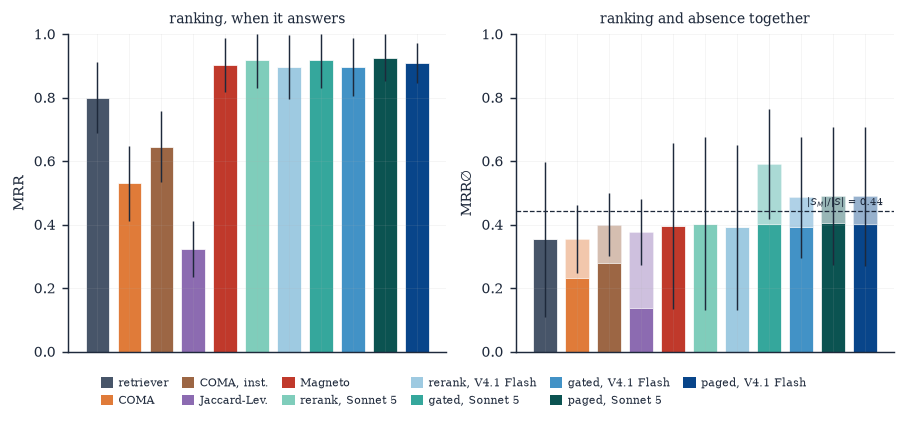

caption: GDC-SM, mean over 10 studies, whiskers one standard deviation; the dashed line is the mean per-study ratio |S_M|/|S| = 0.44


,label,n_studies,mrr_mean,mrr_std,mrr_abstain_mean,mrr_abstain_std
0,retriever,10,0.800,0.112,0.353,0.243
1,COMA,10,0.531,0.118,0.355,0.107
2,"COMA, inst.",10,0.646,0.111,0.400,0.099
3,Jaccard-Lev.,10,0.323,0.088,0.376,0.104
4,Magneto,10,0.903,0.086,0.396,0.262
5,"rerank, Sonnet 5",10,0.917,0.087,0.403,0.273
6,"rerank, V4.1 Flash",10,0.896,0.100,0.391,0.261
7,"gated, Sonnet 5",10,0.917,0.086,0.591,0.174
8,"gated, V4.1 Flash",10,0.896,0.092,0.486,0.192
9,"paged, Sonnet 5",10,0.926,0.073,0.491,0.217


In [5]:
# --- Figure 1: GDC, mean over studies -------------------------------
pairs, names, n_src, n_gold = CORPUS[GDC]
CEIL_GDC = n_gold / n_src
FIELDS = ["mrr", "abstain_recall", "mrr_abstain"]

PS_GDC = per_study(GDC, DESIGN[GDC], pairs, names)
B1 = mean_spread(PS_GDC, FIELDS)
# Per study, so the line is the mean of each study's own ratio, not the
# corpus ratio: on GDC those run from 0.09 to 0.88.
STUDY_CEIL = (PS_GDC["n_gold_columns"] / PS_GDC["n_columns"]).groupby(
    PS_GDC["pair"]).first()
CEIL_BAR = STUDY_CEIL.mean()
print(f"per-study |S_M|/|S|: mean {CEIL_BAR:.3f}, "
      f"range {STUDY_CEIL.min():.3f} to {STUDY_CEIL.max():.3f}  "
      f"(pooled over columns it is {CEIL_GDC:.3f})")
B1.to_csv(TABDIR / "fig1_gdc_per_study.csv", index=False)

fig, axes = plt.subplots(1, 2, figsize=(W2, 2.9))
bar_panel(axes[0], B1["label"], B1["mrr_mean"], B1["colour"],
          err=B1["mrr_std"], ylabel="MRR")
bar_panel(axes[1], B1["label"], None, B1["colour"],
          split=(B1["rank term"].values, B1["abst term"].values),
          err=B1["mrr_abstain_std"], ceiling=CEIL_BAR,
          ylabel=r"MRR$\varnothing$")
axes[0].set_title("ranking, when it answers", fontsize=7.5)
axes[1].set_title("ranking and absence together", fontsize=7.5)
fig.tight_layout()
legend_below(fig, B1["label"], B1["colour"], ncol=6, y=0.02)
save(fig, "fig1_gdc")
plt.show()
# For the caption, since it is no longer drawn on the figure.
print(f"caption: GDC-SM, mean over {int(B1['n_studies'].max())} studies, "
      "whiskers one standard deviation; the dashed line is the mean per-study "
      f"ratio |S_M|/|S| = {CEIL_BAR:.2f}")
display(B1[["label", "n_studies", "mrr_mean", "mrr_std", "mrr_abstain_mean",
            "mrr_abstain_std"]].round(3))

## Figure 2: Valentine, by source

Same two panels per corpus. The ceiling is high wherever absence is rare, which
is why these panels agree with each other far more than GDC's two do.

wrote figures/fig2_valentine.pdf and .png


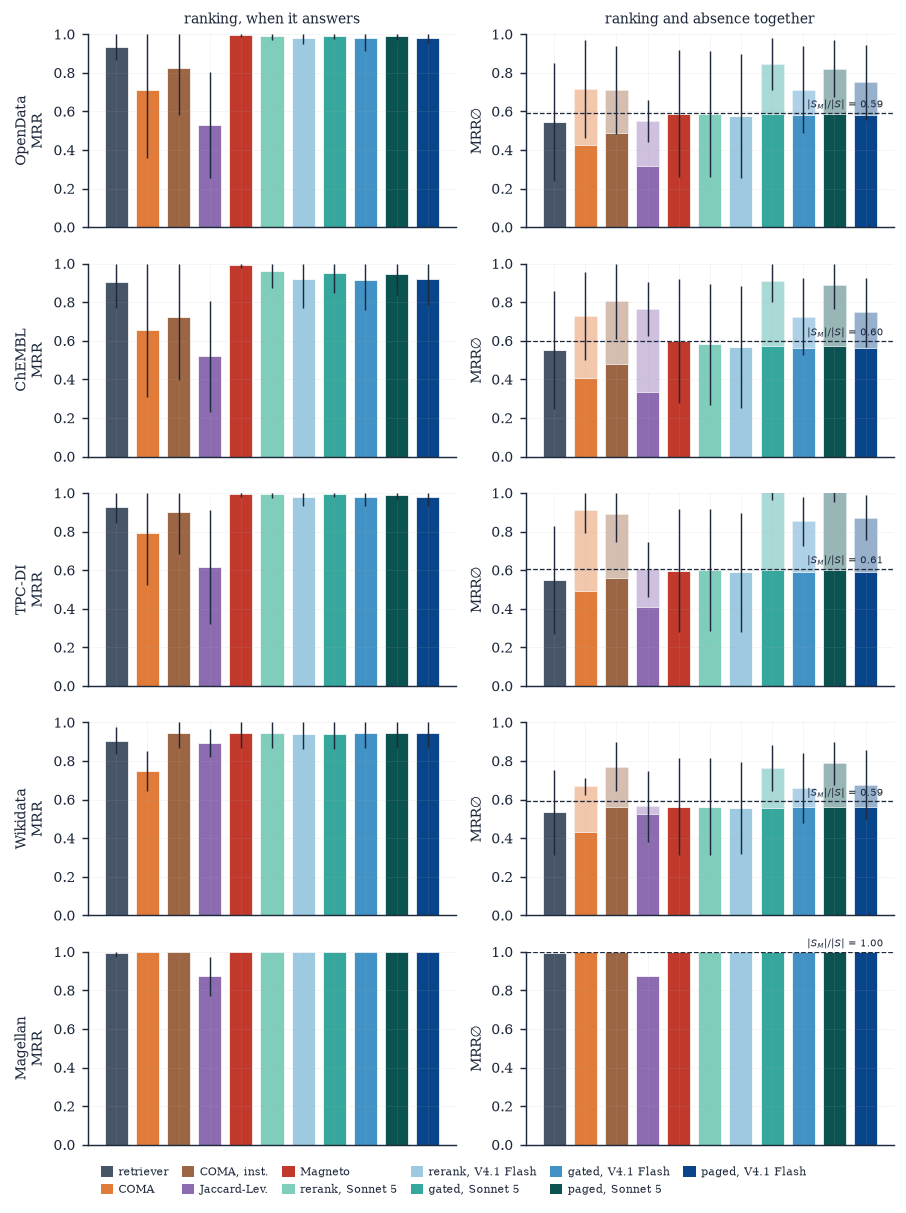

caption: Valentine, mean over the schema pairs of each source, whiskers one standard deviation; each dashed line is that source's mean per-study ratio |S_M|/|S|


In [6]:
# --- Figure 2: Valentine, one row per source -----------------------
# Per study, like Figure 1. These corpora have hundreds of small pairs, so the
# spread is what the pooled number hides.
present = [c for c in VALENTINE if DESIGN[c]]
fig, axes = plt.subplots(len(present), 2, figsize=(W2, 1.8 * len(present)),
                         squeeze=False)
V2 = []
for ri, (ax_row, c) in enumerate(zip(axes, present)):
    pairs_c, names_c, n_src_c, n_gold_c = CORPUS[c]
    ps = per_study(c, DESIGN[c], pairs_c, names_c)
    B = mean_spread(ps, FIELDS)
    ceil = ((ps["n_gold_columns"] / ps["n_columns"])
            .groupby(ps["pair"]).first().mean())
    V2.append(B.assign(corpus=SHORT[c]))

    bar_panel(ax_row[0], B["label"], B["mrr_mean"], B["colour"],
              err=B["mrr_std"], ylabel="MRR")
    bar_panel(ax_row[1], B["label"], None, B["colour"],
              split=(B["rank term"].values, B["abst term"].values),
              err=B["mrr_abstain_std"], ceiling=ceil,
              ylabel=r"MRR$\varnothing$")
    ax_row[0].set_ylabel(f"{SHORT[c]}\nMRR")
    ax_row[1].set_ylabel(r"MRR$\varnothing$")
    if ri == 0:
        ax_row[0].set_title("ranking, when it answers", fontsize=7.5)
        ax_row[1].set_title("ranking and absence together", fontsize=7.5)
fig.tight_layout()
legend_below(fig, B["label"], B["colour"], ncol=6, y=0.01)
save(fig, "fig2_valentine")
plt.show()
print("caption: Valentine, mean over the schema pairs of each source, "
      "whiskers one standard deviation; each dashed line is that source's "
      "mean per-study ratio |S_M|/|S|")
pd.concat(V2).to_csv(TABDIR / "fig2_valentine.csv", index=False)

## Table A: GDC-SM, unfiltered

In [7]:
SHOW = ["arm", "model", "calls_per_column", "mrr", "recall@1", "recall@20",
        "mrr_abstain", "precision_committed", "f1_committed", "f1_evaluated"]


def headline(corpus, runs_of, pairs, names, *, order=RETRIEVER, group_by=None):
    rows = []
    r = retriever_row(corpus, pairs, names, order=order)
    rows.append({"arm": "retriever", "model": "", "calls_per_column": 0.0, **r})
    comp = competitor_rows(corpus, pairs, order=order)
    for x in comp.to_dict("records") if len(comp) else []:
        rows.append({**x, "arm": x["label"], "model": "",
                     "calls_per_column": x["calls"] / max(x["n_columns"], 1)})
    for x in scored(corpus, runs_of, pairs).to_dict("records"):
        rows.append(x)
    T = pd.DataFrame(rows)
    return T[[c for c in SHOW if c in T.columns]].round(3)


pairs, names, n_src, n_gold = CORPUS[GDC]
TABLE_A = headline(GDC, DESIGN[GDC], pairs, names)
TABLE_A.to_csv(TABDIR / "tableA_gdc.csv", index=False)
print(f"GDC-SM, pooled over {n_src} source columns, unfiltered")
display(TABLE_A)

GDC-SM, pooled over 569 source columns, unfiltered


,arm,model,calls_per_column,mrr,recall@1,recall@20,mrr_abstain,precision_committed,f1_committed,f1_evaluated
0,retriever,,0.000,0.812,0.456,0.927,0.235,0.207,0.322,0.322
1,COMA,,0.000,0.521,0.309,0.402,0.360,0.181,0.264,0.218
2,"COMA, inst.",,0.000,0.627,0.378,0.517,0.372,0.218,0.319,0.267
3,Jaccard-Lev.,,0.000,0.304,0.166,0.363,0.382,0.116,0.161,0.117
4,Magneto,,1.005,0.903,0.564,0.919,0.264,0.258,0.399,0.398
5,rerank,Sonnet 5,1.000,0.913,0.568,0.923,0.265,0.258,0.401,0.401
6,rerank,V4.1 Flash,1.000,0.896,0.552,0.927,0.260,0.251,0.390,0.390
7,gated,Sonnet 5,1.000,0.915,0.568,0.907,0.524,0.351,0.503,0.401
8,gated,V4.1 Flash,1.000,0.896,0.552,0.927,0.409,0.297,0.442,0.390
9,paged,Sonnet 5,6.070,0.924,0.575,0.919,0.393,0.299,0.449,0.406


## Table B: Valentine, pooled over the five sources

One table, not five. Pooling weights each source column equally, so OpenData's
6,825 columns dominate Wikidata's 60; the per-source split is Figure 2.

In [8]:
# --- Table B: Valentine, pooled ------------------------------------------
# Pooled by concatenating the five sources' runs and scoring once, so a column
# counts the same wherever it came from.
V_PAIRS, V_NAMES = [], []
for c in VALENTINE:
    V_PAIRS += CORPUS[c][0]
    V_NAMES += CORPUS[c][1]
V_SRC = sum(CORPUS[c][2] for c in VALENTINE)
V_GOLD = sum(CORPUS[c][3] for c in VALENTINE)

rows = []
for arm in ARMS:
    for m in MODELS:
        parts = [DESIGN[c][arm, m] for c in VALENTINE if (arm, m) in DESIGN[c]]
        if len(parts) != len(VALENTINE):
            have = [SHORT[c] for c in VALENTINE if (arm, m) in DESIGN[c]]
            print(f"not whole: {arm} / {MODELS[m][0]}: {have or 'nothing'}")
            continue
        runs = pd.concat(parts, ignore_index=True)
        s = report.score(runs, V_PAIRS, results=RUNS, corpus="valentine",
                         kind=arm).iloc[0]
        rows.append({**s, "arm": arm, "model": MODELS[m][0]})

TABLE_B = pd.DataFrame(rows)
if len(TABLE_B):
    TABLE_B = TABLE_B[[c for c in SHOW if c in TABLE_B.columns]].round(3)
    TABLE_B.to_csv(TABDIR / "tableB_valentine.csv", index=False)
    print(f"Valentine, pooled over {V_SRC:,} source columns, "
          f"ceiling {V_GOLD / V_SRC:.3f}")
    display(TABLE_B)

Valentine, pooled over 12,953 source columns, ceiling 0.671


,arm,model,calls_per_column,mrr,recall@1,recall@20,mrr_abstain,precision_committed,f1_committed,f1_evaluated
0,rerank,Sonnet 5,1.00,0.983,0.976,0.998,0.659,0.654,0.783,0.783
1,rerank,V4.1 Flash,1.00,0.966,0.952,0.998,0.648,0.638,0.764,0.764
2,gated,Sonnet 5,1.00,0.980,0.975,0.988,0.857,0.822,0.892,0.783
3,gated,V4.1 Flash,1.00,0.968,0.957,0.991,0.753,0.720,0.822,0.769
4,paged,Sonnet 5,1.10,0.979,0.974,0.986,0.844,0.809,0.884,0.782
5,paged,V4.1 Flash,1.07,0.965,0.953,0.988,0.771,0.735,0.830,0.765


## Figure 3: what declining does, GDC

Three panels over the same 569 columns. The first two are counts, the third the
precision they produce. `rerank` cannot decline, so its first panel is the
whole gold-free half by construction.

wrote figures/fig3_declining.pdf and .png


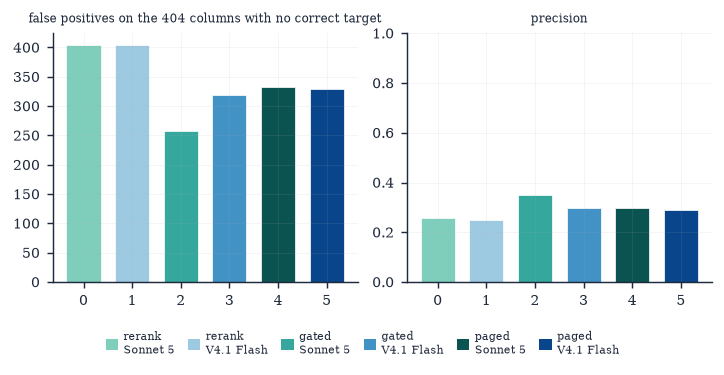

,arm,model,key,wrong on unmatched,right on matched,precision
0,rerank,Sonnet 5,claude-sonnet-5,404,147,0.258
1,rerank,V4.1 Flash,deepseek-v4.1-flash-cloud,404,143,0.251
2,gated,Sonnet 5,claude-sonnet-5,257,147,0.351
3,gated,V4.1 Flash,deepseek-v4.1-flash-cloud,319,143,0.297
4,paged,Sonnet 5,claude-sonnet-5,333,149,0.299
5,paged,V4.1 Flash,deepseek-v4.1-flash-cloud,330,144,0.291


In [9]:
# --- Figure 3: what declining does ---------------------------------------
pairs, names, n_src, n_gold = CORPUS[GDC]
rows = []
for (arm, m), runs in DESIGN[GDC].items():
    s = report.score(runs, pairs, results=RUNS, corpus=GDC, kind=arm).iloc[0]
    rows.append({"arm": arm, "model": MODELS[m][0], "key": m,
                 "wrong on unmatched": s["fp_invented"],
                 "right on matched": s["tp"],
                 "precision": s["precision_committed"]})
D3 = in_arm_order(pd.DataFrame(rows).sort_values("model"))
D3.to_csv(TABDIR / "fig3_declining.csv", index=False)

fig, axes = plt.subplots(1, 2, figsize=(W2 * 4 / 5, 2.5))
panels = [("wrong on unmatched", f"false positives on the {n_src - n_gold} "
           "columns with no correct target"),
          ("precision", "precision")]
labels = [f"{r.arm}\n{r.model}" for r in D3.itertuples()]
cols = [colour_of(r.key, r.arm) for r in D3.itertuples()]
for ax, (field, title) in zip(axes, panels):
    ax.bar(np.arange(len(D3)), D3[field], color=cols, width=0.7,
           edgecolor="white", lw=0.4)
    #ax.set_xticks(np.arange(len(D3)), labels, fontsize=5.6)
    ax.set_title(title, fontsize=6.4)
axes[1].set_ylim(0, 1)
fig.tight_layout()
legend_below(fig, labels, cols, ncol=6, y=0.01)
save(fig, "fig3_declining")
plt.show()
display(D3.round(3))

In [10]:
D3

,arm,model,key,wrong on unmatched,right on matched,precision
0,rerank,Sonnet 5,claude-sonnet-5,404,147,0.258348
1,rerank,V4.1 Flash,deepseek-v4.1-flash-cloud,404,143,0.251318
2,gated,Sonnet 5,claude-sonnet-5,257,147,0.350835
3,gated,V4.1 Flash,deepseek-v4.1-flash-cloud,319,143,0.296680
4,paged,Sonnet 5,claude-sonnet-5,333,149,0.299197
5,paged,V4.1 Flash,deepseek-v4.1-flash-cloud,330,144,0.290909


## Simulated source filters

`mutual` and `zerosrc` remove source columns and never touch a prompt, so a
filtered run is the unfiltered run with those columns recorded as pruned and
every surviving column left alone. That makes them simulable from runs already
on disk, which is how the cells nobody paid for are filled.

It is a **paired** comparison: the model's answers are held fixed and only the
filter varies, so the filter's effect is not confounded with the model's
run-to-run noise. A real filtered run is unpaired, and on GDC that noise moves
MRR with absence by about 0.01 and paged's call count by 12%. The validation
cell measures it against V4.1 Flash, where both the real and the simulated run
exist.

A target rule cannot be simulated: `zero` changes the candidate list every
prompt carries, so the answers would have to be asked again.

In [11]:
# --- Simulating a source-only filter --------------------------------------
SIMDIR = REPO / "results" / "simulated"      # never inside results/runs
SOURCE_ONLY = ("mutual", "zerosrc")

# What `run_paging` writes for a column the filter removed before any call.
PRUNED_RECORD = {
    "n_blocks_available": 0, "accepted_block": None, "stop_reason": "pruned",
    "api_calls": 0, "accepted": False, "abstained": True, "answered": True,
    "committed": False, "tokens_in": 0, "tokens_out": 0, "wall_ms": 0.0,
    "error": "", "ranking": [], "blocks": [],
}


def dropped_for(corpus, pair, rules, order=RETRIEVER):
    """The source columns `rules` removes, from the retrieval order alone."""
    raw = json.loads(cache.retrieval_path(RUNS, corpus, pair["name"], order)
                     .read_text(encoding="utf-8"))["rankings"]
    ranked = {k: [(t, float(v)) for t, v in r] for k, r in raw.items()}
    return set(pruning.plan(ranked, rules).skip())


def simulate_filter(corpus, model, rules, *, order=RETRIEVER, arms=ARMS):
    """
    The unfiltered runs of `model` with `rules` applied after the fact, written
    under `results/simulated` so nothing can mistake them for sent calls.
    """
    if set(pruning.normalise(rules)) - set(SOURCE_ONLY):
        raise ValueError(f"{rules!r} is not a source-only rule; a target rule "
                         "changes the prompts and cannot be simulated")
    pairs, names, _, _ = CORPUS[corpus]
    by_name = {cache.fs_safe(p["name"]): p for p in pairs}
    inv = tagged(inventory.scan(RUNS, corpus=corpus, pairs=names,
                                kinds=tuple(arms)))
    inv = inv[(inv["model"] == model) & (inv["rep"] == 1) & (inv["prune"] == "")
              & (inv["retriever"] == order) & (inv["variant"] == VARIANT)
              & ((inv["kind"] != "paged") & (inv["top_k"] == TOP_K)
                 | (inv["kind"] == "paged") & (inv["window"] == WINDOW)
                 & (inv["threshold"] == TAU))]

    SIMDIR.mkdir(parents=True, exist_ok=True)
    tag = pruning.tag(rules)
    for r in inv.itertuples():
        drop = dropped_for(corpus, by_name[r.pair], rules, order)
        out = json.loads(Path(r.path).read_text(encoding="utf-8"))
        out["trace"]["columns"] = [
            {"source_column": c["source_column"], **PRUNED_RECORD}
            if c["source_column"] in drop else c
            for c in out["trace"]["columns"]]
        meta = out["trace"].setdefault("metadata", {})
        meta["prune"] = {"rules": list(pruning.normalise(rules)),
                         "csls_k": pruning.CSLS_K, "sources": sorted(drop),
                         "n_sources_dropped": len(drop), "targets": [],
                         "n_targets_dropped": 0, "emptied": []}
        meta["simulated_from"] = Path(r.path).name
        name = Path(r.path).name
        for knob in (f"__k{TOP_K}__", f"__th{TAU:.2f}__"):
            if knob in name:
                name = name.replace(knob, f"{knob[:-2]}__p{tag}__")
                break
        (SIMDIR / name).write_text(json.dumps(out), encoding="utf-8")

    sim = tagged(inventory.scan(SIMDIR, corpus=corpus, pairs=names,
                                kinds=tuple(arms)))
    return sim[(sim["model"] == model) & (sim["prune"] == tag)]

In [12]:
# --- How far a simulated filter is from a real one ------------------------
# V4.1 Flash has both, so the gap is the model's run-to-run noise rather than
# anything the simulation does. `rerank` cannot decline, so a reshuffled tail
# moves nothing it reports; the arms that can decline flip on some columns.
VAL_MODEL, VAL_RULES = "deepseek-v4.1-flash-cloud", "zerosrc"
sim = simulate_filter(GDC, VAL_MODEL, VAL_RULES)
real_of, _, pairs, _ = cells(GDC, prune=VAL_RULES)

FIELDS = ["n_pruned", "mrr", "mrr_abstain", "recall@1", "f1_committed",
          "calls_per_column"]
rows = []
for arm in ARMS:
    if (arm, VAL_MODEL) not in real_of:
        continue
    a = report.score(real_of[arm, VAL_MODEL], pairs, results=RUNS,
                     corpus=GDC, kind=arm).iloc[0]
    b = report.score(sim[sim["kind"] == arm], pairs, results=SIMDIR,
                     corpus=GDC, kind=arm).iloc[0]
    for f in FIELDS:
        rows.append({"arm": arm, "metric": f, "real": a[f], "simulated": b[f],
                     "gap": b[f] - a[f]})
VALIDATION = pd.DataFrame(rows)
VALIDATION.to_csv(TABDIR / "simulation_validation.csv", index=False)
display(VALIDATION.round(4))
print(f"largest gap in MRR with absence: "
      f"{VALIDATION[VALIDATION['metric'] == 'mrr_abstain']['gap'].abs().max():.4f}")

,arm,metric,real,simulated,gap
0,rerank,n_pruned,81.0000,81.0000,0.0000
1,rerank,mrr,0.8956,0.8956,0.0000
2,rerank,mrr_abstain,0.4021,0.4021,0.0000
3,rerank,recall@1,0.5521,0.5521,0.0000
4,rerank,f1_committed,0.4380,0.4380,0.0000
5,rerank,calls_per_column,0.8600,0.8600,0.0000
6,gated,n_pruned,81.0000,81.0000,0.0000
7,gated,mrr,0.8904,0.8964,0.0059
8,gated,mrr_abstain,0.5007,0.5095,0.0088
9,gated,recall@1,0.5444,0.5521,0.0077


largest gap in MRR with absence: 0.0129


## Table C: the full grid, protocol by filter

Every protocol and both models under each filter, with the retriever and
Magneto's protocol under the same filters so a reader can attribute the gain.

In [13]:
# --- Table C: protocol x filter ------------------------------------------
# A source-only filter nobody ran is simulated from the unfiltered run and
# marked as such. Its call count is arithmetic rather than sampled: a source
# rule makes exactly one call for each column it keeps.
rows = []
for prune, flabel in FILTERS.items():
    runs_of, short, pairs, n_src = cells(GDC, prune=prune)
    for (arm, m), runs in runs_of.items():
        s = report.score(runs, pairs, results=RUNS, corpus=GDC, kind=arm).iloc[0]
        rows.append({"filter": flabel, "arm": arm, "model": MODELS[m][0],
                     "pruned": int(s["n_pruned"]), "mrr": s["mrr"],
                     "mrr_abstain": s["mrr_abstain"],
                     "f1_committed": s["f1_committed"],
                     "calls/col": s["calls_per_column"], "source": "run"})
    missing = [(a, m) for a in ARMS for m in MODELS if (a, m) not in runs_of]
    if prune and not (set(pruning.normalise(prune)) - set(SOURCE_ONLY)):
        for arm, m in missing:
            sim = simulate_filter(GDC, m, prune)
            sub = sim[sim["kind"] == arm]
            if not len(sub):
                continue
            s = report.score(sub, pairs, results=SIMDIR, corpus=GDC,
                             kind=arm).iloc[0]
            base = cells(GDC)[0].get((arm, m))
            calls = s["calls_per_column"]
            if base is not None:
                b = report.score(base, pairs, results=RUNS, corpus=GDC,
                                 kind=arm).iloc[0]
                calls = b["calls_per_column"] * (1 - s["n_pruned"] / n_src)
            rows.append({"filter": flabel, "arm": arm, "model": MODELS[m][0],
                         "pruned": int(s["n_pruned"]), "mrr": s["mrr"],
                         "mrr_abstain": s["mrr_abstain"],
                         "f1_committed": s["f1_committed"],
                         "calls/col": calls, "source": "simulated"})
    elif prune:
        for arm, m in missing:
            print(f"not whole and not simulable: {flabel} / {arm} / {MODELS[m][0]}")

TABLE_C = pd.DataFrame(rows)
TABLE_C.to_csv(TABDIR / "tableC_grid.csv", index=False)
n_sim = int((TABLE_C["source"] == "simulated").sum())
print(f"{len(TABLE_C)} cells, {n_sim} of them simulated from the unfiltered run")
# MRR first: a source filter removes columns the model was answering, so it
# falls while MRR with absence rises. Reporting only the second hides the cost.
for field in ("mrr", "mrr_abstain", "f1_committed", "calls/col"):
    print("")
    print(field)
    display(TABLE_C.pivot_table(index=["arm", "model"], columns="filter",
                                values=field, sort=False).round(3))
display(TABLE_C[TABLE_C["source"] == "simulated"].round(3))

# What each filter costs in ranking and buys in absence, against no filter.
base = TABLE_C[TABLE_C["filter"] == "none"].set_index(["arm", "model"])
delta = TABLE_C[TABLE_C["filter"] != "none"].copy()
delta["d mrr"] = [r["mrr"] - base.loc[(r["arm"], r["model"]), "mrr"]
                  for _, r in delta.iterrows()]
delta["d mrr_abstain"] = [
    r["mrr_abstain"] - base.loc[(r["arm"], r["model"]), "mrr_abstain"]
    for _, r in delta.iterrows()]
print("")
print("change against no filter")
display(delta.pivot_table(index=["arm", "model"], columns="filter",
                          values=["d mrr", "d mrr_abstain"],
                          sort=False).round(3))

30 cells, 3 of them simulated from the unfiltered run

mrr


filter              none  zero-source  mutual  mutual+zero-target  zero-target
arm    model                                                                  
rerank Sonnet 5    0.913        0.913   0.845               0.837        0.908
       V4.1 Flash  0.896        0.896   0.821               0.819        0.885
gated  Sonnet 5    0.915        0.915   0.838               0.838        0.909
       V4.1 Flash  0.896        0.890   0.818               0.826        0.893
paged  Sonnet 5    0.924        0.924   0.860               0.849        0.924
       V4.1 Flash  0.908        0.904   0.835               0.832        0.900


mrr_abstain


filter              none  zero-source  mutual  mutual+zero-target  zero-target
arm    model                                                                  
rerank Sonnet 5    0.265        0.407   0.635               0.633        0.263
       V4.1 Flash  0.260        0.402   0.628               0.628        0.257
gated  Sonnet 5    0.524        0.594   0.733               0.740        0.541
       V4.1 Flash  0.409        0.501   0.680               0.702        0.373
paged  Sonnet 5    0.393        0.500   0.712               0.742        0.518
       V4.1 Flash  0.393        0.515   0.687               0.707        0.451


f1_committed


...


calls/col


filter             none  zero-source  mutual  mutual+zero-target  zero-target
arm    model                                                                 
rerank Sonnet 5    1.00        0.858    0.59                0.59         1.00
       V4.1 Flash  1.00        0.860    0.59                0.59         1.00
gated  Sonnet 5    1.00        0.858    0.59                0.59         1.00
       V4.1 Flash  1.00        0.860    0.59                0.59         1.00
paged  Sonnet 5    6.07        5.206    3.47                2.04         4.51
       V4.1 Flash  6.04        5.240    2.86                1.73         3.82

,filter,arm,model,pruned,mrr,mrr_abstain,f1_committed,calls/col,source
9,zero-source,rerank,Sonnet 5,81,0.913,0.407,0.450,0.858,simulated
10,zero-source,gated,Sonnet 5,81,0.915,0.594,0.540,0.858,simulated
11,zero-source,paged,Sonnet 5,81,0.924,0.500,0.495,5.206,simulated



change against no filter


d mrr                                       d mrr_abstain                                      
filter            zero-source mutual mutual+zero-target zero-target   zero-source mutual mutual+zero-target zero-target
arm    model                                                                                                           
rerank V4.1 Flash       0.000 -0.074             -0.077      -0.010         0.142  0.369              0.368      -0.003
       Sonnet 5         0.000 -0.068             -0.076      -0.005         0.142  0.370              0.368      -0.001
gated  V4.1 Flash      -0.006 -0.079             -0.071      -0.003         0.091  0.271              0.292      -0.036
       Sonnet 5         0.000 -0.076             -0.077      -0.005         0.070  0.210              0.217       0.018
paged  V4.1 Flash      -0.004 -0.073             -0.076      -0.007         0.122  0.293              0.314       0.058
       Sonnet 5         0.000 -0.064             -0.074       0.001         0.107  0.319              0.349       0.125

## Figure 4: cost against quality

Calls per column against committed $F_1$, with an arrow from each unfiltered
cell to its filtered one. It earns its place only if the frontier is not
already legible in Table C.

wrote figures/fig4_cost_quality.pdf and .png


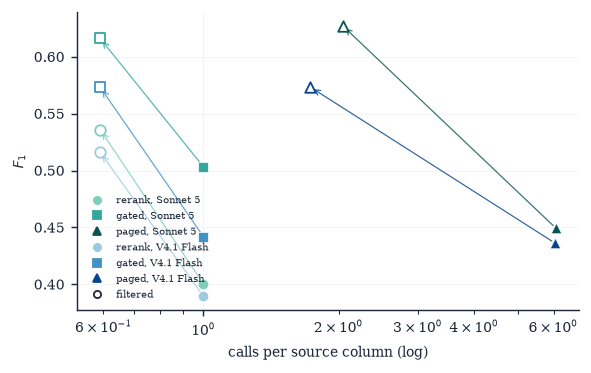

In [14]:
# --- Figure 4: cost against quality --------------------------------------
MARK = {"rerank": "o", "gated": "s", "paged": "^"}
fig, ax = plt.subplots(figsize=(W1 * 1.35, 2.9))
base = TABLE_C[TABLE_C["filter"] == "none"].set_index(["arm", "model"])
tip = TABLE_C[TABLE_C["filter"] == "mutual+zero-target"].set_index(["arm", "model"])
KEY_OF = {lab: k for k, (lab, _) in MODELS.items()}
for key, b in base.iterrows():
    arm, model = key
    colour = colour_of(KEY_OF[model], arm)
    ax.scatter(b["calls/col"], b["f1_committed"], marker=MARK[arm], s=34,
               color=colour, zorder=4, edgecolor="white", lw=0.4)
    if key in tip.index:
        t = tip.loc[key]
        ax.annotate("", xy=(t["calls/col"], t["f1_committed"]),
                    xytext=(b["calls/col"], b["f1_committed"]),
                    arrowprops=dict(arrowstyle="->", lw=0.7, color=colour,
                                    alpha=0.8))
        ax.scatter(t["calls/col"], t["f1_committed"], marker=MARK[arm], s=34,
                   facecolor="white", edgecolor=colour, lw=1.0, zorder=5)
ax.set_xscale("log")
ax.set_xlabel("calls per source column (log)")
ax.set_ylabel("$F_1$")
handles = [plt.Line2D([], [], marker=MARK[a], ls="",
                      color=colour_of(k, a), ms=4, label=f"{a}, {lab}")
           for k, (lab, _) in MODELS.items() for a in ARMS]
handles += [plt.Line2D([], [], marker="o", ls="", mfc="white", mec=C_INK,
                       color=C_INK, ms=4, label="filtered")]
ax.legend(handles=handles, fontsize=5.8, frameon=False, loc="lower left")
fig.tight_layout()
save(fig, "fig4_cost_quality")
plt.show()

## Table D: the two retrieval orders

Never pooled across orders: one ceiling row cannot describe both. The declines
column is the result, since the unmatched columns are the same under either
order.

In [15]:
# --- Table D: two orders, paired -----------------------------------------
rows = []
for order in ORDERS:
    pairs, names, n_src, n_gold = CORPUS[GDC]
    base = retriever_row(GDC, pairs, names, order=order)
    runs_of, short, _, _ = cells(GDC, order=order)
    for (arm, m), runs in runs_of.items():
        s = report.score(runs, pairs, results=RUNS, corpus=GDC, kind=arm).iloc[0]
        rows.append({"order": order, "ret MRR": base["mrr"],
                     "ret R@20": base["recall@20"], "arm": arm,
                     "model": MODELS[m][0], "mrr": s["mrr"],
                     "mrr_abstain": s["mrr_abstain"],
                     "declines": int(s["n_declined"]),
                     "declined with gold": int(s["fn_abstained"])})
    for s in short:
        print(f"not whole: {order} / {s[0]} / {s[1]}")

TABLE_D = pd.DataFrame(rows).round(3)
TABLE_D.to_csv(TABDIR / "tableD_orders.csv", index=False)
display(TABLE_D)

,order,ret MRR,ret R@20,arm,model,mrr,mrr_abstain,declines,declined with gold
0,qwen,0.812,0.927,rerank,Sonnet 5,0.913,0.265,0,0
1,qwen,0.812,0.927,rerank,V4.1 Flash,0.896,0.260,0,0
2,qwen,0.812,0.927,gated,Sonnet 5,0.915,0.524,150,3
3,qwen,0.812,0.927,gated,V4.1 Flash,0.896,0.409,87,2
4,qwen,0.812,0.927,paged,Sonnet 5,0.924,0.393,71,0
5,qwen,0.812,0.927,paged,V4.1 Flash,0.908,0.393,74,0
6,magneto,0.702,0.772,rerank,Sonnet 5,0.857,0.249,0,0
7,magneto,0.702,0.772,rerank,V4.1 Flash,0.800,0.232,0,0
8,magneto,0.702,0.772,gated,Sonnet 5,0.848,0.636,230,8
9,magneto,0.702,0.772,gated,V4.1 Flash,0.816,0.609,214,2


## Table E: what `mutual` removed

Each removed column classified by what the unfiltered run did with it. This is
what separates a filter that buys correctness from one that only buys calls.

In [16]:
# --- Table E: what mutual removed ----------------------------------------
from evaluation.matching import classify_columns

pairs, names, n_src, n_gold = CORPUS[GDC]
removed, with_gold, pairs_lost = set(), set(), 0
for p in pairs:
    name = cache.fs_safe(p["name"])
    raw = json.loads(cache.retrieval_path(RUNS, GDC, p["name"], RETRIEVER)
                     .read_text(encoding="utf-8"))["rankings"]
    order = {k: [(t, float(s)) for t, s in v] for k, v in raw.items()}
    gold = {}
    for s, t in p["ground_truth"]:
        gold.setdefault(str(s), set()).add(t)
    for col in pruning.plan(order, "mutual").skip():
        key = report.namespaced(name, col)
        removed.add(key)
        if col in gold:
            with_gold.add(key)
            pairs_lost += len(gold[col])

n_gold_pairs = sum(len(p["ground_truth"]) for p in pairs)
print(f"mutual removes {len(removed)} of {n_src} columns "
      f"({len(removed) / n_src:.1%}); {len(with_gold)} have gold, carrying "
      f"{pairs_lost} of {n_gold_pairs} pairs ({pairs_lost / n_gold_pairs:.1%})")

LABEL = {"TP": "gold first", "FP_FN_wrong": "wrong target first",
         "FP_invented": "invented, no gold", "FN_abstained": "declined, had gold",
         "TN_declined": "declined, correctly",
         "no_answer_gold": "unreadable, had gold",
         "no_answer_free": "unreadable, no gold"}
rows = []
for (arm, m), runs in DESIGN[GDC].items():
    rk, gt, com, abst = report.pool(runs.itertuples(), pairs)
    cls = classify_columns(rk, gt, com, abstained=abst)
    counts = {}
    for key in removed:
        if key in cls:
            counts[cls[key]] = counts.get(cls[key], 0) + 1
    rows.append({"arm": arm, "model": MODELS[m][0],
                 **{LABEL[k]: counts.get(k, 0) for k in LABEL}})

TABLE_E = in_arm_order(pd.DataFrame(rows).sort_values("model"))
TABLE_E.to_csv(TABDIR / "tableE_mutual_removed.csv", index=False)
display(TABLE_E)

mutual removes 234 of 569 columns (41.1%); 12 have gold, carrying 18 of 259 pairs (6.9%)


,arm,model,gold first,wrong target first,"invented, no gold","declined, had gold","declined, correctly","unreadable, had gold","unreadable, no gold"
0,rerank,Sonnet 5,11,1,222,0,0,0,0
1,rerank,V4.1 Flash,11,1,222,0,0,0,0
2,gated,Sonnet 5,10,2,130,0,92,0,0
3,gated,V4.1 Flash,11,1,177,0,45,0,0
4,paged,Sonnet 5,10,2,181,0,41,0,0
5,paged,V4.1 Flash,11,1,181,0,41,0,0


## Figure 5: depth sweep

Replayed on the recorded walks, so no new calls. A rule can only decline an
acceptance, never walk on past one. The marker is the first depth that loses
nothing against the full walk, which is what justifies the chosen $d$.

wrote figures/fig5_depth.pdf and .png


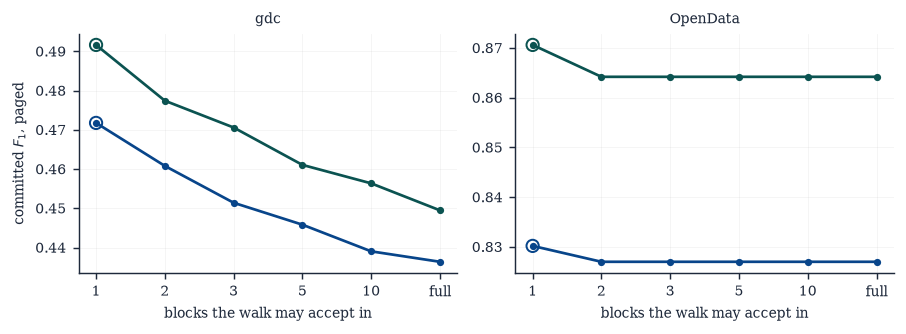

In [17]:
# --- Figure 5: depth sweep -----------------------------------------------
DEPTHS = [1, 2, 3, 5, 10, None]
DEPTH_ON = [GDC, "valentine/opendata"]

fig, axes = plt.subplots(1, len(DEPTH_ON), figsize=(W2, 2.6), squeeze=False)
rows = []
for ax, c in zip(axes[0], DEPTH_ON):
    pairs_c = CORPUS[c][0]
    for (arm, m), runs in DESIGN[c].items():
        if arm != "paged":
            continue
        colour = colour_of(m, arm)
        f1 = [walk_rules.score_replay(runs, pairs_c, results=RUNS, corpus=c,
                                      cap=d)["f1_committed"] for d in DEPTHS]
        ax.plot(range(len(DEPTHS)), f1, marker="o", ms=3, color=colour)
        full = f1[-1]
        first = next((i for i, v in enumerate(f1) if v >= full - 1e-9), None)
        if first is not None:
            ax.scatter([first], [f1[first]], s=46, facecolor="none",
                       edgecolor=colour, lw=1.1, zorder=5)
        for d, v in zip(DEPTHS, f1):
            rows.append({"corpus": SHORT.get(c, c), "model": MODELS[m][0],
                         "depth": d or "full", "f1_committed": v})
    ax.set_xticks(range(len(DEPTHS)), [str(d) if d else "full" for d in DEPTHS])
    ax.set_xlabel("blocks the walk may accept in")
    ax.set_title(SHORT.get(c, c), fontsize=7.5)
axes[0][0].set_ylabel("committed $F_1$, paged")
fig.tight_layout()
save(fig, "fig5_depth")
plt.show()
pd.DataFrame(rows).to_csv(TABDIR / "fig5_depth.csv", index=False)

## Table F: block size

$w \in \{5, 10, 20, 50\}$ on GDC. Only a model with the whole sweep on disk can
appear; the cell says which.

In [18]:
# --- Table F: block size -------------------------------------------------
rows = []
for w in (5, 10, 20, 50):
    runs_of, short, pairs, n_src = cells(GDC, kinds=["paged"], window=w)
    for (arm, m), runs in runs_of.items():
        s = report.score(runs, pairs, results=RUNS, corpus=GDC,
                         kind="paged").iloc[0]
        rows.append({"window": w, "model": MODELS[m][0],
                     "mrr_abstain": s["mrr_abstain"],
                     "f1_committed": s["f1_committed"],
                     "calls/col": s["calls_per_column"]})
TABLE_F = pd.DataFrame(rows)
if len(TABLE_F):
    TABLE_F.to_csv(TABDIR / "tableF_window.csv", index=False)
    display(TABLE_F.pivot_table(index="window", columns="model",
                                values=["mrr_abstain", "f1_committed",
                                        "calls/col"]).round(3))
else:
    print("no window sweep is whole for the models in this design")

calls/col            f1_committed            mrr_abstain           
model   Sonnet 5 V4.1 Flash     Sonnet 5 V4.1 Flash    Sonnet 5 V4.1 Flash
window                                                                    
5           3.90        NaN        0.397        NaN       0.265        NaN
10          6.62        NaN        0.431        NaN       0.330        NaN
20          6.07       6.04        0.449      0.436       0.393      0.393
50          4.55        NaN        0.513        NaN       0.519        NaN

## Appendix: the CSLS neighbourhood size

Read off the retrieval orders alone, so it costs nothing and needs no run. What
each $k$ would remove, and how much gold it would take.

In [19]:
# --- Appendix: CSLS k sweep ----------------------------------------------
rows = []
for c in [GDC, "valentine/opendata"]:
    pairs_c, names_c, n_src_c, _ = CORPUS[c]
    for k in (1, 3, 5, 10, 20, 50):
        drop = gold_hit = 0
        n_pairs_lost = n_pairs_all = 0
        for p in pairs_c:
            raw = json.loads(cache.retrieval_path(RUNS, c, p["name"], RETRIEVER)
                             .read_text(encoding="utf-8"))["rankings"]
            order = {a: [(t, float(s)) for t, s in v] for a, v in raw.items()}
            M, S, _ = pruning.score_matrix(order)
            drop_s, _ = pruning.masks(M, ("mutual",), csls_k=k)
            gold = {}
            for s, t in p["ground_truth"]:
                gold.setdefault(str(s), set()).add(t)
            n_pairs_all += sum(len(v) for v in gold.values())
            for s, d in zip(S, drop_s):
                if not d:
                    continue
                drop += 1
                if s in gold:
                    gold_hit += 1
                    n_pairs_lost += len(gold[s])
        rows.append({"corpus": SHORT.get(c, c), "csls_k": k, "dropped": drop,
                     "dropped %": 100 * drop / n_src_c,
                     "with gold": gold_hit,
                     "gold pairs lost %": 100 * n_pairs_lost / max(n_pairs_all, 1)})
CSLS_K = pd.DataFrame(rows)
CSLS_K.to_csv(TABDIR / "appendix_csls_k.csv", index=False)
display(CSLS_K.round(2))

,corpus,csls_k,dropped,dropped %,with gold,gold pairs lost %
0,gdc,1,201,35.33,9,5.79
1,gdc,3,209,36.73,10,5.79
2,gdc,5,221,38.84,11,6.56
3,gdc,10,234,41.12,12,6.95
4,gdc,20,247,43.41,14,8.11
5,gdc,50,260,45.69,16,8.88
6,OpenData,1,1700,24.72,328,7.17
7,OpenData,3,1841,26.77,337,7.37
8,OpenData,5,1988,28.91,387,8.46
9,OpenData,10,2165,31.49,459,10.04
